# Causal AI: Rủi ro địa chính trị (GPR), cơ cấu năng lượng và nhập khẩu năng lượng ròng 

**Kết quả của nghiên cứu: khám phá ban đầu (exploratory).**

In [ ]:
import os, json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from linearmodels.panel import PanelOLS
from sklearn.linear_model import RidgeCV, LassoCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3, 'axes.spines.top': False, 'axes.spines.right': False})
os.makedirs('output', exist_ok=True)
SEED = 20260
RNG = np.random.default_rng(SEED)

# ---- Cấu hình phân tích  ----
BASE_YEARS = (2010, 2013)   # cửa sổ đo mức phơi nhiễm, trước Crimea 2014
END_YEAR   = 2022           # mẫu chính 2010-2022 (2023 chỉ còn 67/139 nước, xem mục 1)
N_PERM, N_SUBSET, N_RCC = 2000, 1000, 500
CRITERIA = dict(
    placebo_size   = (0.02, 0.08),  # tỷ lệ bác bỏ H0 ở mức 5% của placebo phải ~5% (kiểm định có đúng kích thước)
    lead_p_min     = 0.10,          # hệ số "lead" (GPR_{t+1} x exposure) phải KHÔNG có ý nghĩa: p > 0.10
    placebo_out_p  = 0.10,          # outcome placebo (đô thị hóa, dân số): p > 0.10
    rcc_shift_se   = 0.25,          # thêm biến ngẫu nhiên: median |Δβ| < 0.25 SE
    rcc_sign       = 0.95,          # và dấu hệ số giữ nguyên trong >= 95% lần
    subset_sign    = 0.90,          # tập con 80%: dấu giữ nguyên >= 90%
    subset_shift_se= 1.00,          # và độ lệch tối đa (percentile 95) <= 1 SE của mẫu đầy đủ
    pretrend_p_min = 0.10,          # Wald chung các hệ số trước sự kiện: p > 0.10
)
print('Cấu hình đã khai báo:'); [print(f'  {k}: {v}') for k, v in CRITERIA.items()]

# ---- Hàm lõi: TWFE nhanh (dùng cho mô phỏng), đã kiểm tra khớp linearmodels ----
def demean_2way(M, ent, tim, n_iter=200, tol=1e-10):
    M = np.asarray(M, float).copy(); one_d = M.ndim == 1
    if one_d: M = M[:, None]
    ne, nt = ent.max()+1, tim.max()+1
    ce, ct = np.bincount(ent, minlength=ne), np.bincount(tim, minlength=nt)
    for _ in range(n_iter):
        old = M.copy()
        for j in range(M.shape[1]):
            M[:, j] -= (np.bincount(ent, M[:, j], ne)/ce)[ent]
            M[:, j] -= (np.bincount(tim, M[:, j], nt)/ct)[tim]
        if np.max(np.abs(M-old)) < tol: break
    return M[:, 0] if one_d else M

def cluster_ols(y, X, cl, k_extra=0):
    X = np.asarray(X, float); y = np.asarray(y, float); n, k = X.shape
    XtX_inv = np.linalg.pinv(X.T @ X); b = XtX_inv @ X.T @ y; e = y - X @ b
    ug = np.unique(cl); G = len(ug); meat = np.zeros((k, k))
    for g in ug:
        s = X[cl == g].T @ e[cl == g]; meat += np.outer(s, s)
    c = G/(G-1) * (n-1)/max(n-k-k_extra, 1)
    V = c * XtX_inv @ meat @ XtX_inv
    return b, np.sqrt(np.diag(V)), V

def twfe(y, X, ent, tim):
    Z = demean_2way(np.column_stack([y, X]), ent, tim)
    return cluster_ols(Z[:, 0], Z[:, 1:], ent, k_extra=ent.max()+tim.max()+1)

Cấu hình đã khai báo:
  placebo_size: (0.02, 0.08)
  lead_p_min: 0.1
  placebo_out_p: 0.1
  rcc_shift_se: 0.25
  rcc_sign: 0.95
  subset_sign: 0.9
  subset_shift_se: 1.0
  pretrend_p_min: 0.1


## 1. Kiểm tra dữ liệu (data audit)

Trước khi ước lượng, kiểm tra độ phủ dữ liệu theo năm, thang đo của outcome, và biến thiên của từng biến.

1850 quan sát x 16 biến | 143 quốc gia | 2010-2023


,n_countries,renewable_obs,renew_mean,Y_mean,Y_median,Y_mean_balanced67
year,,,,,,
2010,134,134,28.1,-36.5,23.3,16.4
2011,133,133,27.7,-31.1,22.9,18.8
2012,136,136,28.1,-30.5,20.4,18.3
2013,137,137,28.0,-27.6,23.7,20.7
2014,136,136,28.1,-29.4,22.6,20.0
2015,137,137,27.7,-26.3,23.3,20.4
2016,137,137,27.6,-23.5,28.8,22.9
2017,139,139,28.5,-23.9,24.2,24.6
2018,139,139,28.4,-21.4,25.2,25.0



GPR có đúng 1 giá trị/năm cho mọi nước? True => số giá trị GPR khác nhau = 14

Outcome: 5 nước thấp nhất / cao nhất (trung bình):
{'South Sudan': -831.0, 'Equatorial Guinea': -765.0, 'Norway': -632.0, 'Angola': -556.0, 'Congo, Rep.': -504.0}
{'Panama': 173.0, 'Hong Kong SAR, China': 207.0, 'Curacao': 207.0, 'Singapore': 275.0, 'Malta': 358.0}

Phương sai nội-quốc-gia / tổng phương sai:
  energy_imports_net   0.054
  renewable_share      0.013
  gdp_per_capita       0.019
  industry_share       0.108
  trade_openness       0.042
  urbanization         0.008


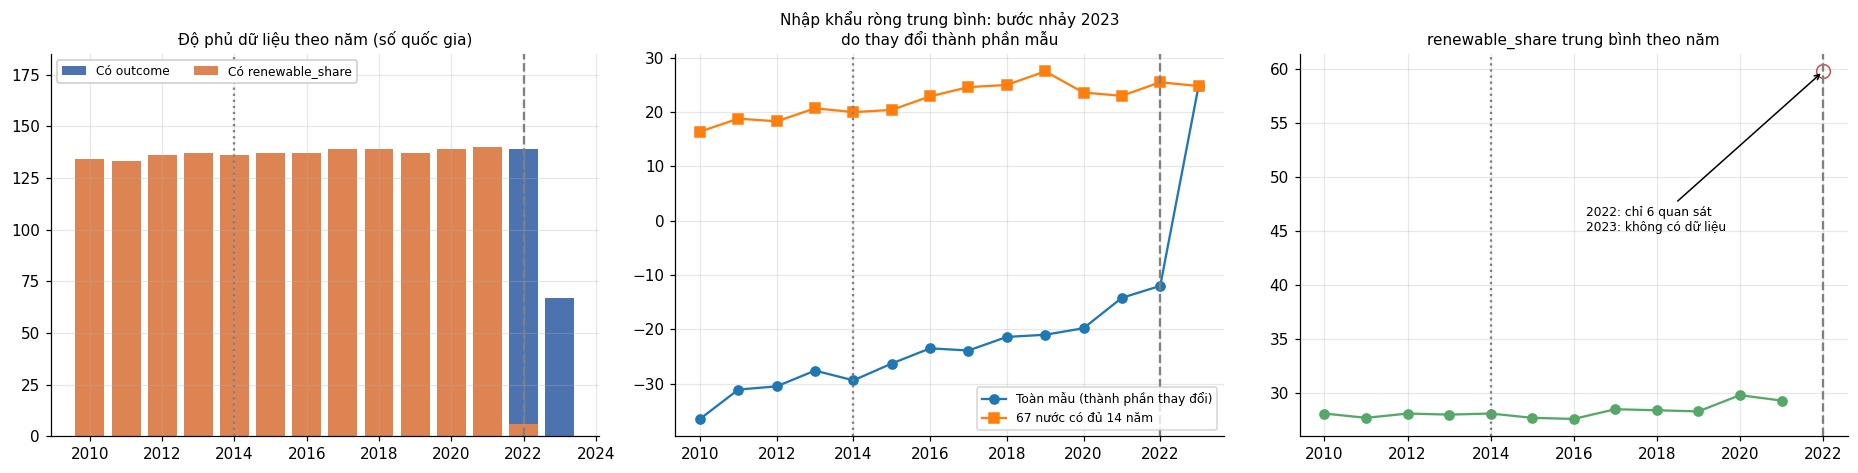

In [2]:
raw = pd.read_csv('input/panel_data.csv')
print(f'{raw.shape[0]} quan sát x {raw.shape[1]} biến | {raw.country_code.nunique()} quốc gia | {raw.year.min()}-{raw.year.max()}')

cov = raw.groupby('year').agg(n_countries=('country_code', 'size'),
                              renewable_obs=('renewable_share', 'count'),
                              renew_mean=('renewable_share', 'mean'),
                              Y_mean=('energy_imports_net', 'mean'),
                              Y_median=('energy_imports_net', 'median')).round(1)
bal = raw.groupby('country_code').size(); full = bal[bal == raw.year.nunique()].index
cov['Y_mean_balanced67'] = raw[raw.country_code.isin(full)].groupby('year')['energy_imports_net'].mean().round(1)
display(cov)

print('\nGPR có đúng 1 giá trị/năm cho mọi nước?', raw.groupby('year').gpr_index.nunique().max() == 1,
      '=> số giá trị GPR khác nhau =', raw.gpr_index.nunique())
print('\nOutcome: 5 nước thấp nhất / cao nhất (trung bình):')
m = raw.groupby('country_name').energy_imports_net.mean().sort_values()
print(m.head(5).round(0).to_dict()); print(m.tail(5).round(0).to_dict())
print('\nPhương sai nội-quốc-gia / tổng phương sai:')
for v in ['energy_imports_net', 'renewable_share', 'gdp_per_capita', 'industry_share', 'trade_openness', 'urbanization']:
    w = (raw[v] - raw.groupby('country_code')[v].transform('mean')).var()
    print(f'  {v:20s} {w/raw[v].var():.3f}')

fig, ax = plt.subplots(1, 3, figsize=(17, 4.4))
ax[0].bar(cov.index, cov.n_countries, color='#4C72B0', label='Có outcome'); ax[0].bar(cov.index, cov.renewable_obs, color='#DD8452', label='Có renewable_share')
ax[0].set_ylim(0, 185); ax[0].set_title('Độ phủ dữ liệu theo năm (số quốc gia)', fontsize=10); ax[0].legend(loc='upper left', fontsize=8, ncol=2, framealpha=1)
ax[1].plot(cov.index, cov.Y_mean, 'o-', label='Toàn mẫu (thành phần thay đổi)'); ax[1].plot(cov.index, cov.Y_mean_balanced67, 's-', label='67 nước có đủ 14 năm')
ax[1].set_title('Nhập khẩu ròng trung bình: bước nhảy 2023\ndo thay đổi thành phần mẫu', fontsize=10); ax[1].legend(fontsize=8, loc='lower right')
r_ = cov.renew_mean.dropna(); ax[2].plot(r_.index[:-1], r_.values[:-1], 'o-', color='#55A868'); ax[2].plot(r_.index[-1:], r_.values[-1:], 'o', mfc='none', mec='#C44E52', ms=9)
ax[2].annotate('2022: chỉ 6 quan sát\n2023: không có dữ liệu', (2022, r_.values[-1]), xytext=(2016.3, 45), fontsize=8, arrowprops=dict(arrowstyle='->'))
ax[2].set_title('renewable_share trung bình theo năm', fontsize=10)
for a_ in ax: a_.axvline(2014, ls=':', c='gray'); a_.axvline(2022, ls='--', c='gray')
plt.tight_layout(); plt.savefig('output/fig_audit.png', dpi=150, bbox_inches='tight'); plt.show()

**Kết luận kiểm toán**

1. `renewable_share` **không có dữ liệu cho 2023 và chỉ có 6 quan sát năm 2022** ⇒ bản cũ đã lấp bằng trung vị (21%) cho toàn bộ các năm này, khiến mức "phơi nhiễm" của hơn 200 quan sát là hằng số giả tạo.
2. Năm 2023 chỉ còn **67/139 quốc gia** (mất mẫu không ngẫu nhiên: các nước xuất khẩu năng lượng lớn biến mất). Bước nhảy của nhập khẩu ròng trung bình từ −12 lên +24.8 là **hiệu ứng thành phần**; trên 67 nước có đủ dữ liệu, giá trị gần như phẳng. Do đó Hình 2 của bản cũ ("nhập khẩu tăng cùng GPR giai đoạn 2020–2023") không thể dùng làm bằng chứng.
3. Thang đo của `energy_imports_net` (Na Uy ≈ −632, Nam Sudan ≈ −831, Malta ≈ +358) phù hợp với **"Energy imports, net (% of energy use)"** của World Bank, *không phải* % GDP như bản cũ ghi. *(Cần đối chiếu lại với nguồn gốc dữ liệu của bạn.)*
4. Chỉ ~5% phương sai của outcome là *nội-quốc-gia*; `renewable_share` gần như bất biến theo thời gian (1.3% phương sai nội-quốc-gia) ⇒ thiết kế dựa trên **mức phơi nhiễm trước cú sốc** là hợp lý.
5. GPR chỉ có 14 giá trị khác nhau (một chuỗi thời gian toàn cầu) ⇒ không thể nhận dạng "tác động của GPR" bằng so sánh giữa các nước cùng năm; chỉ nhận dạng được **phản ứng khác biệt** của các nước có mức phơi nhiễm khác nhau trước cùng một cú sốc.

**Quyết định về mẫu:** mẫu chính = **2010–2022** (2023 dùng làm kiểm tra độ vững).

## 2. Xây dựng biến và thiết kế nhận dạng

**Thiết kế (continuous-exposure difference-in-differences / shift-share đơn giản).**
Cú sốc `GPR_t` là chung cho mọi nước nên không thể so sánh "nước chịu cú sốc" với "nước không chịu". Thay vào đó, mỗi nước có một **mức phơi nhiễm cố định trước cú sốc**:

- `Fossil_i` = 100 − tỷ trọng năng lượng tái tạo trung bình 2010–2013 (trước Crimea). Cố định ⇒ không bị ảnh hưởng ngược bởi cú sốc sau này.
- Mô hình: **Y_it = α_i + λ_t + β · (GPR_t × Fossil_i) + Σ_k γ_k (GPR_t × Z_ik) + ε_it**, trong đó Z_i là các đặc điểm cơ bản trước 2014 (GDP/người, công nghiệp, mở cửa thương mại, đô thị hóa, dân số).
- `α_i`, `λ_t` hấp thụ mọi khác biệt cố định giữa các nước và mọi cú sốc chung theo năm (giá dầu, COVID, …).
- **β > 0** nghĩa là khi GPR tăng, các nước phụ thuộc hóa thạch nhiều hơn tăng nhập khẩu ròng *nhiều hơn* các nước ít phụ thuộc ⇒ tương thích với giả thuyết "green hedging" (năng lượng tái tạo làm giảm độ nhạy).
- GPR và `Fossil` được **chuẩn hóa (1 SD)** nên β đọc được trực tiếp: *thay đổi của nhập khẩu ròng (điểm % năng lượng sử dụng) khi GPR cao hơn 1 SD ở nước có Fossil cao hơn 1 SD so với nước trung bình.*

**Giả định nhận dạng (cần nói rõ, không kiểm định được hoàn toàn):** không có xu hướng khác biệt theo mức phơi nhiễm nào trùng thời điểm với biến động GPR, ngoài những gì các Z_i × GPR đã kiểm soát. Event study (mục 4) chỉ kiểm tra được phần *trước 2014*.

In [3]:
d0 = raw[raw.year <= END_YEAR].copy()
d0['lgdp'] = np.log(d0.gdp_per_capita)
win = raw[(raw.year >= BASE_YEARS[0]) & (raw.year <= BASE_YEARS[1])].copy(); win['lgdp'] = np.log(win.gdp_per_capita)
bs = win.groupby('country_code').agg(ren0=('renewable_share', 'mean'), lgdp0=('lgdp', 'mean'), ind0=('industry_share', 'mean'),
                                      trade0=('trade_openness', 'mean'), urb0=('urbanization', 'mean'), lpop0=('log_population', 'mean'))
n_all = raw.country_code.nunique()
bs_ok = bs.dropna()
print(f'Quốc gia có đủ biến cơ sở 2010–2013: {len(bs_ok)}/{n_all} (loại {n_all-len(bs_ok)} nước thiếu dữ liệu giai đoạn cơ sở)')

bs_ok = bs_ok.copy(); bs_ok['fossil0'] = 100 - bs_ok.ren0
std = lambda s: (s - s.mean())/s.std()
bs_ok['F'] = std(bs_ok.fossil0)
ZB = ['lgdp0', 'ind0', 'trade0', 'urb0', 'lpop0']
for c in ZB: bs_ok[c+'_s'] = std(bs_ok[c])
SD_F = bs_ok.fossil0.std()

# GPR chuẩn hóa theo 13 năm của mẫu (2010-2022); z cho cả 2023 dùng cùng trung bình/độ lệch chuẩn
gy = raw.groupby('year').gpr_index.first(); gy3 = raw.groupby('year').gpr_threats.first()
mu, sd = gy[gy.index <= END_YEAR].mean(), gy[gy.index <= END_YEAR].std()
mu3, sd3 = gy3[gy3.index <= END_YEAR].mean(), gy3[gy3.index <= END_YEAR].std()
zmap = ((gy - mu)/sd).to_dict(); z3map = ((gy3 - mu3)/sd3).to_dict()
SD_GPR = sd
print(f'1 SD GPR = {SD_GPR:.1f} điểm (trung bình {mu:.1f}); 1 SD Fossil_i = {SD_F:.1f} điểm %')

def build(raw_df, end_year):
    x = raw_df[raw_df.year <= end_year].merge(bs_ok[['F', 'fossil0'] + [c+'_s' for c in ZB]], left_on='country_code', right_index=True)
    x = x.sort_values(['country_code', 'year']).reset_index(drop=True)
    x['ent'] = x.country_code.astype('category').cat.codes.values
    x['tim'] = (x.year - x.year.min()).values
    x['z'] = x.year.map(zmap); x['z3'] = x.year.map(z3map)
    x['z_lag'] = (x.year-1).map(zmap); x['z_lead'] = (x.year+1).map(zmap)
    x['D'] = x.z * x.F; x['D3'] = x.z3 * x.F; x['D_lag'] = x.z_lag * x.F; x['D_lead'] = x.z_lead * x.F
    for c in ZB: x['zx_'+c] = x.z * x[c+'_s']; x['zlx_'+c] = x.z_lag * x[c+'_s']
    x['lgdp'] = np.log(x.gdp_per_capita)
    return x
dm = build(raw, END_YEAR)
ZX = ['zx_'+c for c in ZB]
print(f'Mẫu chính: {len(dm)} quan sát, {dm.country_code.nunique()} quốc gia, {dm.year.nunique()} năm')
print('Hệ số tương quan Fossil_i với các đặc điểm cơ bản (để thấy vì sao phải kiểm soát Z_i x GPR):')
print(bs_ok[['F'] + [c+'_s' for c in ZB]].corr().iloc[0, 1:].round(2).to_dict())

Quốc gia có đủ biến cơ sở 2010–2013: 128/143 (loại 15 nước thiếu dữ liệu giai đoạn cơ sở)
1 SD GPR = 16.3 điểm (trung bình 118.1); 1 SD Fossil_i = 27.0 điểm %
Mẫu chính: 1636 quan sát, 128 quốc gia, 13 năm
Hệ số tương quan Fossil_i với các đặc điểm cơ bản (để thấy vì sao phải kiểm soát Z_i x GPR):
{'lgdp0_s': 0.71, 'ind0_s': 0.23, 'trade0_s': 0.31, 'urb0_s': 0.63, 'lpop0_s': -0.09}


In [4]:
# Bảng 1: thống kê mô tả tính trực tiếp từ dữ liệu (mẫu chính 2010-2022)
vars_ = {'energy_imports_net': 'Nhập khẩu năng lượng ròng (% năng lượng sử dụng)', 'gpr_index': 'Chỉ số GPR', 'renewable_share': 'Tỷ trọng tái tạo (%)',
         'gdp_per_capita': 'GDP/người (USD)', 'trade_openness': 'Độ mở thương mại (% GDP)', 'industry_share': 'Tỷ trọng công nghiệp (% GDP)',
         'fdi_inflows': 'FDI ròng vào (% GDP)', 'urbanization': 'Đô thị hóa (%)'}
t1 = dm[list(vars_)].describe().T[['count', 'mean', 'std', 'min', 'max']].round(2)
t1.index = [vars_[i] for i in t1.index]; t1.columns = ['N', 'Trung bình', 'Độ lệch chuẩn', 'Min', 'Max']
t1['N'] = t1['N'].astype(int)
t1.to_csv('output/table1_descriptive.csv'); display(t1)
print('\nBiến phơi nhiễm (cấp quốc gia, n =', len(bs_ok), '):'); print(bs_ok.fossil0.describe().round(2).to_dict())

,N,Trung bình,Độ lệch chuẩn,Min,Max
Nhập khẩu năng lượng ròng (% năng lượng sử dụng),1636,-19.50,164.11,-1169.23,450.18
Chỉ số GPR,1636,118.04,15.71,100.10,154.80
Tỷ trọng tái tạo (%),1515,28.41,26.06,0.00,97.00
GDP/người (USD),1636,28484.04,25952.60,1124.77,149025.12
Độ mở thương mại (% GDP),1615,89.75,59.38,2.70,442.62
Tỷ trọng công nghiệp (% GDP),1633,29.15,11.97,2.39,78.06
FDI ròng vào (% GDP),1616,5.17,23.64,-391.56,452.22
Đô thị hóa (%),1636,64.79,20.12,16.21,100.00



Biến phơi nhiễm (cấp quốc gia, n = 128 ):
{'count': 128.0, 'mean': 71.51, 'std': 26.99, 'min': 4.4, '25%': 53.49, '50%': 79.49, '75%': 94.04, 'max': 100.0}


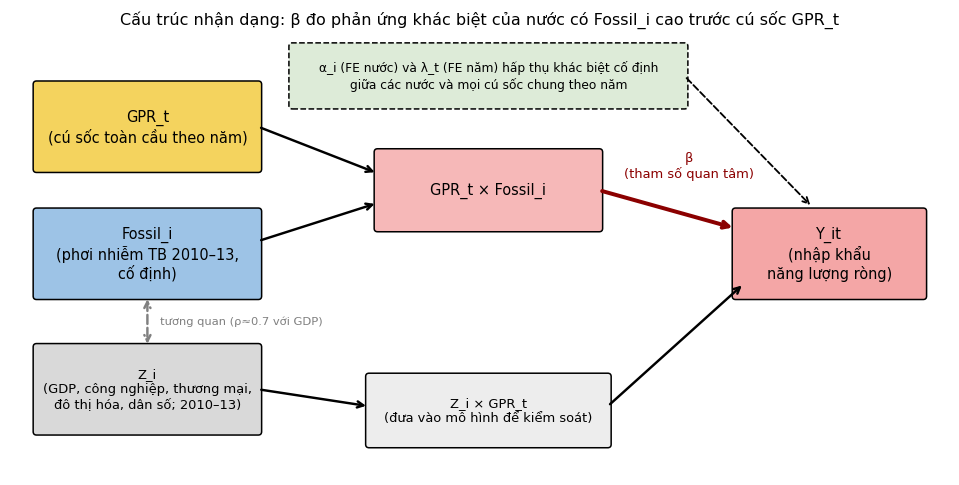

In [5]:
# DAG phản ánh đúng thiết kế (thay cho DAG ở bản cũ chứa các biến không có trong dữ liệu)
import matplotlib.patches as mp
fig, ax = plt.subplots(figsize=(11, 5.2)); ax.axis('off'); ax.set_xlim(0, 11); ax.set_ylim(0, 5.2)
def box(x, y, w, h, t, c, fs=9.5, ls='-'):
    ax.add_patch(mp.FancyBboxPatch((x-w/2, y-h/2), w, h, boxstyle='round,pad=0.04', fc=c, ec='k', ls=ls)); ax.text(x, y, t, ha='center', va='center', fontsize=fs)
def arrow(p1, p2, c='k', ls='-', lw=1.6, style='->'): ax.annotate('', xy=p2, xytext=p1, arrowprops=dict(arrowstyle=style, lw=lw, color=c, ls=ls))
box(1.6, 4.1, 2.6, 1.0, 'GPR_t\n(cú sốc toàn cầu theo năm)', '#F4D35E')
box(1.6, 2.6, 2.6, 1.0, 'Fossil_i\n(phơi nhiễm TB 2010–13,\ncố định)', '#9DC3E6')
box(1.6, 1.0, 2.6, 1.0, 'Z_i\n(GDP, công nghiệp, thương mại,\nđô thị hóa, dân số; 2010–13)', '#D9D9D9', fs=8.5)
box(5.6, 3.35, 2.6, 0.9, 'GPR_t × Fossil_i', '#F6B8B8')
box(9.6, 2.6, 2.2, 1.0, 'Y_it\n(nhập khẩu\nnăng lượng ròng)', '#F4A6A6')
box(5.6, 0.75, 2.8, 0.8, 'Z_i × GPR_t\n(đưa vào mô hình để kiểm soát)', '#EDEDED', fs=8.5)
box(5.6, 4.7, 4.6, 0.7, 'α_i (FE nước) và λ_t (FE năm) hấp thụ khác biệt cố định\ngiữa các nước và mọi cú sốc chung theo năm', '#DDEBD8', fs=8, ls='--')
arrow((2.9, 4.1), (4.3, 3.55)); arrow((2.9, 2.75), (4.3, 3.2))
arrow((6.9, 3.35), (8.5, 2.9), c='darkred', lw=2.6); ax.text(7.95, 3.5, 'β\n(tham số quan tâm)', color='darkred', fontsize=8.5, ha='center')
arrow((2.9, 1.0), (4.2, 0.8)); arrow((7.0, 0.8), (8.6, 2.25))
arrow((1.6, 2.1), (1.6, 1.5), c='gray', ls='--', style='<->'); ax.text(1.75, 1.8, 'tương quan (ρ≈0.7 với GDP)', fontsize=7.5, color='gray', va='center')
arrow((7.9, 4.7), (9.4, 3.15), ls='--', lw=1.2)
ax.set_title('Cấu trúc nhận dạng: β đo phản ứng khác biệt của nước có Fossil_i cao trước cú sốc GPR_t', fontsize=10.5)
plt.savefig('output/fig_dag.png', dpi=150, bbox_inches='tight'); plt.show()

## 3. Ước lượng chính (TWFE) và độ vững theo đặc tả

SE cluster theo quốc gia (143 cụm). Đặc tả (2) là **đặc tả chính**, được chọn *trước* theo thiết kế: country FE + year FE + `Z_i × GPR_t`. Các cột còn lại là kiểm tra độ vững, **không** được dùng để chọn kết quả.

In [7]:
def fit_panel(df_, y, xcols):
    d = df_.set_index(['country_code', 'year'])
    res = PanelOLS(d[y], d[xcols], entity_effects=True, time_effects=True, drop_absorbed=True).fit(cov_type='clustered', cluster_entity=True)
    return res

def row(res, name, df_, target='D', label=''):
    b, s = res.params[target], res.std_errors[target]; p = res.pvalues[target]; ci = res.conf_int().loc[target]
    return dict(Đặc_tả=label, β=b, SE=s, p=p, CI_lo=ci.iloc[0], CI_hi=ci.iloc[1], N=int(res.nobs), Cụm=df_.country_code.nunique())

dm['Y_w'] = dm.energy_imports_net.clip(*dm.energy_imports_net.quantile([.01, .99]))
dm['Y_asinh'] = np.arcsinh(dm.energy_imports_net/10)
TV = ['lgdp', 'trade_openness', 'industry_share', 'fdi_inflows', 'urbanization', 'log_population']
specs = []
r1 = fit_panel(dm, 'energy_imports_net', ['D']);               specs.append(row(r1, '', dm, label='(1) FE nước + FE năm'))
r2 = fit_panel(dm, 'energy_imports_net', ['D'] + ZX);          specs.append(row(r2, '', dm, label='(2) + Z_i × GPR_t  [CHÍNH]'))
dcc = dm.dropna(subset=TV).copy()
r3 = fit_panel(dcc, 'energy_imports_net', ['D'] + ZX + TV);    specs.append(row(r3, '', dcc, label='(3) + biến kiểm soát biến thiên theo thời gian'))
d4 = dm[dm.year >= BASE_YEARS[0]+1].copy()
for c in ZB: d4['zlx_'+c] = d4['zlx_'+c]
ZLX = ['zlx_'+c for c in ZB]
r4 = fit_panel(d4, 'energy_imports_net', ['D_lag'] + ZLX);     specs.append(row(r4, '', d4, target='D_lag', label='(4) GPR trễ 1 năm'))
dm23 = build(raw, 2023); r5 = fit_panel(dm23, 'energy_imports_net', ['D'] + ['zx_'+c for c in ZB]); specs.append(row(r5, '', dm23, label='(5) gồm 2023 (mẫu mất cân bằng)'))
r6 = fit_panel(dm, 'Y_w', ['D'] + ZX);                         specs.append(row(r6, '', dm, label='(6) Y winsor 1%/99%'))
r7 = fit_panel(dm, 'Y_asinh', ['D'] + ZX);                     specs.append(row(r7, '', dm, label='(7) Y = asinh(Y/10)  [β theo đơn vị log-ish]'))
r8 = fit_panel(dm, 'energy_imports_net', ['D3'] + ['zx_'+c for c in ZB]); specs.append(row(r8, '', dm, target='D3', label='(8) GPR Threats thay GPR'))
d9 = dm[dm.year != 2020]; r9 = fit_panel(d9, 'energy_imports_net', ['D'] + ZX); specs.append(row(r9, '', d9, label='(9) bỏ năm COVID 2020'))
t2 = pd.DataFrame(specs).set_index('Đặc_tả')
t2['Ý nghĩa 5%'] = np.where(t2.p < .05, 'Có', 'Không')
t2.round(4).to_csv('output/table2_main.csv'); display(t2.round(4))
RES_MAIN = r2; B, SE_B, P_B = r2.params['D'], r2.std_errors['D'], r2.pvalues['D']
print(f'\nĐẶC TẢ CHÍNH: β = {B:.3f} (SE {SE_B:.3f}), p = {P_B:.3f}, CI95% [{r2.conf_int().loc["D"].iloc[0]:.2f}, {r2.conf_int().loc["D"].iloc[1]:.2f}]')
print(f'Diễn giải: GPR cao hơn 1 SD (~{SD_GPR:.0f} điểm) làm nhập khẩu ròng của nước có Fossil cao hơn 1 SD (~{SD_F:.0f} điểm %) '
      f'thay đổi {B:+.2f} điểm % năng lượng sử dụng so với nước trung bình. Độ lệch chuẩn của Y = {dm.energy_imports_net.std():.0f}, nên đây là {abs(B)/dm.energy_imports_net.std():.3f} SD của Y.')

,β,SE,p,CI_lo,CI_hi,N,Cụm,Ý nghĩa 5%
Đặc_tả,,,,,,,,
(1) FE nước + FE năm,1.1341,0.8285,0.1712,-0.4910,2.7593,1636,128,Không
(2) + Z_i × GPR_t [CHÍNH],2.3200,1.5311,0.1299,-0.6833,5.3233,1636,128,Không
(3) + biến kiểm soát biến thiên theo thời gian,2.5620,1.4220,0.0718,-0.2275,5.3515,1592,128,Không
(4) GPR trễ 1 năm,1.0681,1.7716,0.5467,-2.4073,4.5434,1512,128,Không
(5) gồm 2023 (mẫu mất cân bằng),2.5696,1.4358,0.0737,-0.2467,5.3859,1703,128,Không
(6) Y winsor 1%/99%,2.0174,1.3436,0.1334,-0.6182,4.6530,1636,128,Không
(7) Y = asinh(Y/10) [β theo đơn vị log-ish],0.0103,0.0179,0.5656,-0.0248,0.0454,1636,128,Không
(8) GPR Threats thay GPR,2.4306,1.5948,0.1277,-0.6977,5.5589,1636,128,Không
(9) bỏ năm COVID 2020,2.6773,1.7047,0.1165,-0.6668,6.0213,1509,128,Không



ĐẶC TẢ CHÍNH: β = 2.320 (SE 1.531), p = 0.130, CI95% [-0.68, 5.32]
Diễn giải: GPR cao hơn 1 SD (~16 điểm) làm nhập khẩu ròng của nước có Fossil cao hơn 1 SD (~27 điểm %) thay đổi +2.32 điểm % năng lượng sử dụng so với nước trung bình. Độ lệch chuẩn của Y = 164, nên đây là 0.014 SD của Y.


## 4. Event study đúng nghĩa và kiểm định xu hướng trước sự kiện

Mô hình: **Y_it = α_i + λ_t + Σ_{k≠ref} β_k (Fossil_i × 1[year = k]) + ε_it**. Hệ số `β_k` đo chênh lệch (so với năm tham chiếu) giữa nước có Fossil cao hơn 1 SD và nước trung bình.

- **Xu hướng song song** ⇔ các `β_k` *trước* sự kiện đồng thời bằng 0. Kiểm định bằng **Wald (dạng F) chung** với ma trận phương sai cluster theo quốc gia — thay cho việc "nhìn residual gần 0".
- Hai sự kiện: **Crimea (2014)**, tham chiếu 2013 (3 năm lead); **Ukraine (2022)**, tham chiếu 2021 (cửa sổ 2016–2022).
- Báo cáo thêm **sai số chuẩn trung bình của các lead** và *minimum detectable effect* (MDE ≈ 2.8 SE) để biết kiểm định có đủ lực hay không. *Không bác bỏ ≠ chứng minh song song.*

,wald_F,df,p,mean_lead_se,n,MDE_80%_power,Đạt tiêu chí (p > 0.10)
"Crimea (ref 2013), F×năm",0.4381,3.0,0.7262,4.7914,1636.0,13.4160,PASS
Crimea + Z_i×năm,1.2452,3.0,0.2962,6.9819,1636.0,19.5494,PASS
"Ukraine (ref 2021), F×năm",1.1526,5.0,0.3363,3.6975,887.0,10.3530,PASS


Hiệu ứng chính β = 2.32; MDE của kiểm định lead (Crimea) = 13.42 => kiểm định KHÔNG đủ lực phát hiện độ lệch cỡ hiệu ứng chính (MDE lớn hơn |β|).


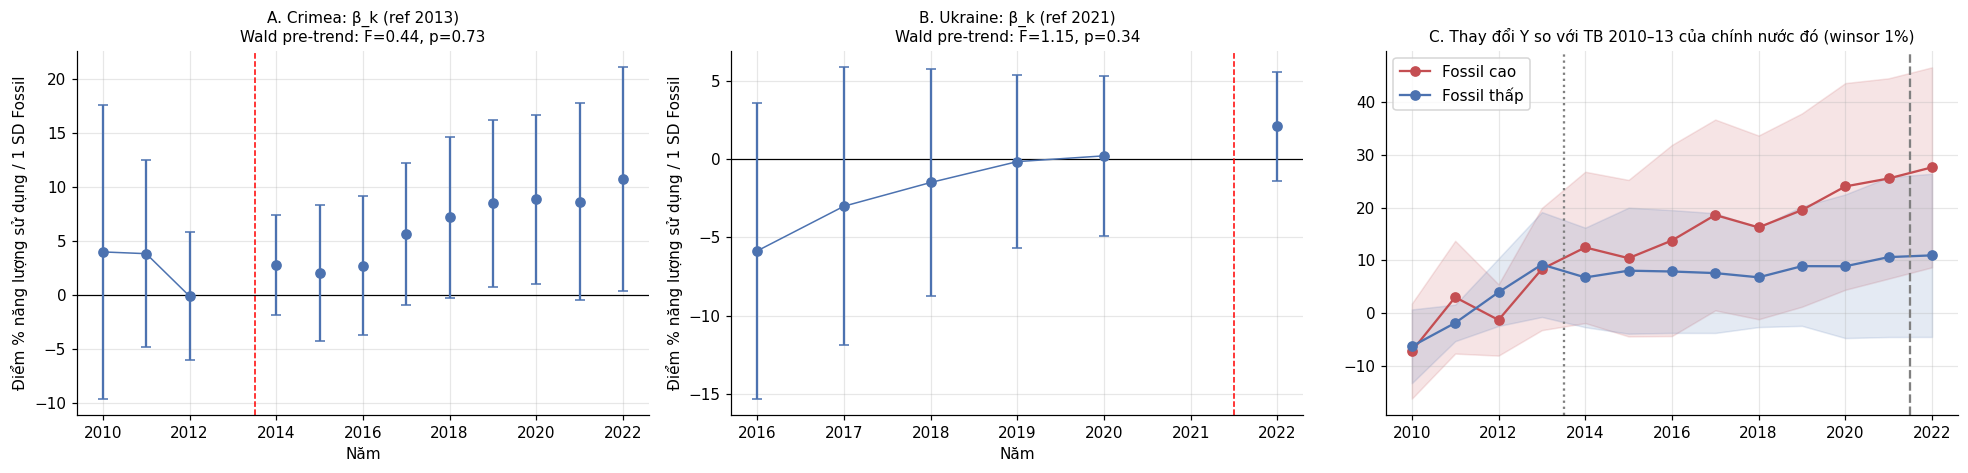

In [8]:
def event_study(df_, years, ref, leads, with_zb=False):
    s = df_[df_.year.isin(years)].copy(); cols = []
    for k in years:
        if k == ref: continue
        s[f'F_{k}'] = s.F * (s.year == k); cols.append(f'F_{k}')
        if with_zb:
            for c in ZB: s[f'{c}_{k}'] = s[c+'_s'] * (s.year == k); cols.append(f'{c}_{k}')
    res = fit_panel(s, 'energy_imports_net', cols)
    ks = [k for k in years if k != ref]
    out = pd.DataFrame({'year': ks, 'b': [res.params[f'F_{k}'] for k in ks], 'se': [res.std_errors[f'F_{k}'] for k in ks]})
    out['lo'], out['hi'] = out.b - 1.96*out.se, out.b + 1.96*out.se
    lc = [f'F_{k}' for k in leads]; b = res.params[lc].values; V = res.cov.loc[lc, lc].values
    W = float(b @ np.linalg.solve(V, b)); q = len(lc); G = s.country_code.nunique()
    pF = stats.f.sf(W/q, q, G-1)
    return out, dict(wald_F=W/q, df=q, p=pF, mean_lead_se=float(out[out.year.isin(leads)].se.mean()), n=int(res.nobs))

es_A,  wA  = event_study(dm, list(range(2010, 2023)), 2013, [2010, 2011, 2012])
es_A2, wA2 = event_study(dm, list(range(2010, 2023)), 2013, [2010, 2011, 2012], with_zb=True)
es_B,  wB  = event_study(dm, list(range(2016, 2023)), 2021, [2016, 2017, 2018, 2019, 2020])
ES = {'Crimea (ref 2013), F×năm': wA, 'Crimea + Z_i×năm': wA2, 'Ukraine (ref 2021), F×năm': wB}
t_es = pd.DataFrame(ES).T; t_es['MDE_80%_power'] = 2.8*t_es.mean_lead_se
t_es['Đạt tiêu chí (p > %.2f)' % CRITERIA['pretrend_p_min']] = np.where(t_es.p > CRITERIA['pretrend_p_min'], 'PASS', 'FAIL')
t_es.round(4).to_csv('output/table3_pretrend.csv'); display(t_es.round(4))
print(f"Hiệu ứng chính β = {B:.2f}; MDE của kiểm định lead (Crimea) = {2.8*wA['mean_lead_se']:.2f} => "
      + ('kiểm định có lực phát hiện độ lệch cỡ hiệu ứng chính.' if 2.8*wA['mean_lead_se'] < abs(B) else 'kiểm định KHÔNG đủ lực phát hiện độ lệch cỡ hiệu ứng chính (MDE lớn hơn |β|).'))

# Xu hướng thô: nhóm Fossil cao (tercile trên) vs thấp (tercile dưới), tương đối so với trung bình 2010-2013 của chính nước đó
dm['tercile'] = pd.qcut(dm.F, 3, labels=['Thấp', 'Giữa', 'Cao']).astype(str)
b0 = dm[dm.year.between(*BASE_YEARS)].groupby('country_code').energy_imports_net.mean()
dm['Y_rel'] = dm.energy_imports_net - dm.country_code.map(b0)
lo_, hi_ = dm.Y_rel.quantile([.01, .99]); dm['Y_rel_w'] = dm.Y_rel.clip(lo_, hi_)
tr = dm.groupby(['tercile', 'year']).Y_rel_w.agg(['mean', 'sem']).reset_index()

fig, ax = plt.subplots(1, 3, figsize=(18, 4.4))
for a, es, ref, ev, ttl, w in [(ax[0], es_A, 2013, 2014, 'A. Crimea: β_k (ref 2013)', wA), (ax[1], es_B, 2021, 2022, 'B. Ukraine: β_k (ref 2021)', wB)]:
    a.axhline(0, c='k', lw=.8); a.axvline(ref+.5, c='r', ls='--', lw=1); a.errorbar(es.year, es.b, yerr=1.96*es.se, fmt='o', capsize=3, c='#4C72B0')
    pre = es.year <= ref; a.plot(es.year[pre], es.b[pre], c='#4C72B0', lw=1)
    a.set_title(ttl + f'\nWald pre-trend: F={w["wald_F"]:.2f}, p={w["p"]:.2f}', fontsize=10); a.set_xlabel('Năm'); a.set_ylabel('Điểm % năng lượng sử dụng / 1 SD Fossil')
for t_, c_ in [('Cao', '#C44E52'), ('Thấp', '#4C72B0')]:
    g = tr[tr.tercile == t_]; ax[2].plot(g.year, g['mean'], 'o-', c=c_, label=f'Fossil {t_.lower()}'); ax[2].fill_between(g.year, g['mean']-1.96*g['sem'], g['mean']+1.96*g['sem'], color=c_, alpha=.15)
ax[2].axvline(2013.5, c='gray', ls=':'); ax[2].axvline(2021.5, c='gray', ls='--'); ax[2].legend(); ax[2].set_title('C. Thay đổi Y so với TB 2010–13 của chính nước đó (winsor 1%)', fontsize=10)
plt.tight_layout(); plt.savefig('output/fig_event_study.png', dpi=150, bbox_inches='tight'); plt.show()

## 5. Double Machine Learning (DML) với FE hai chiều và cross-fitting theo quốc gia

Mục đích của DML ở đây: **kiểm soát phi tuyến/tương tác** của các biến gây nhiễu (GDP, công nghiệp, thương mại, …) mà mô hình tuyến tính (cột 3 bảng 2) không bắt được, và cho ước lượng β có suy luận hợp lệ.

Quy trình (mô hình tuyến tính từng phần sau khi loại FE):
1. Loại country FE và year FE khỏi `Y` và `D = GPR_t × Fossil_i` (khử trung bình hai chiều).
2. Hồi quy `Ỹ` và `D̃` lên đặc trưng `W = [Z_i × GPR_t, GPR_t, Z_i, biến kiểm soát (mức gốc và đã khử FE)]` bằng Ridge / Lasso / Random Forest, **cross-fitting K=5 theo quốc gia** (không để một nước xuất hiện ở cả tập train và test), lặp 5 lần với các phân chia khác nhau, lấy trung vị.
3. `β̂ = Σ r_D r_Y / Σ r_D²`, **SE cluster theo quốc gia** tính từ hàm điểm trực giao.
4. Đối chiếu chéo với `econml.LinearDML` dùng cùng phân chia theo nhóm.

Khác bản cũ: không còn CATE tuyến tính theo X (vốn tạo ra "green hedging" do dạng hàm); không dùng `cv=2` ngẫu nhiên.

In [9]:
def make_learner(name, seed):
    if name == 'Ridge': return make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 30)))
    if name == 'Lasso': return make_pipeline(StandardScaler(), LassoCV(cv=5, n_alphas=40, max_iter=20000, random_state=seed))
    if name == 'RandomForest': return RandomForestRegressor(n_estimators=300, min_samples_leaf=5, max_features=0.5, n_jobs=-1, random_state=seed)

def folds_by_country(ent, K, seed):
    G = ent.max()+1; return np.random.default_rng(seed).permutation(np.arange(G) % K)[ent]

def crossfit_resid(target, feats, fold, name, seed):
    res = np.zeros(len(target))
    for k in np.unique(fold):
        tr, te = fold != k, fold == k
        res[te] = target[te] - make_learner(name, seed).fit(feats[tr], target[tr]).predict(feats[te])
    return res

def dml_plr(Yd, Dd, feats, ent, name, K=5, R=5, seed=SEED):
    G = ent.max()+1; th, se2 = [], []
    for r in range(R):
        f = folds_by_country(ent, K, seed+r)
        rY, rD = crossfit_resid(Yd, feats, f, name, seed+r), crossfit_resid(Dd, feats, f, name, seed+r)
        t = (rD @ rY)/(rD @ rD); s = np.bincount(ent, rD*(rY - t*rD), G)
        th.append(t); se2.append((s**2).sum()*G/(G-1)/(rD @ rD)**2)
    th, se2 = np.array(th), np.array(se2); tm = np.median(th)
    return tm, float(np.sqrt(np.median(se2 + (th-tm)**2))), th

dd = dcc.copy().reset_index(drop=True); dd['ent'] = pd.factorize(dd.country_code)[0]; dd['tim'] = dd.year - dd.year.min()
Yd = demean_2way(dd.energy_imports_net.values, dd.ent.values, dd.tim.values); Dd = demean_2way(dd.D.values, dd.ent.values, dd.tim.values)
# Đặc trưng W: (i) tương tác Z_i x GPR_t (cần thiết vì sau khi khử FE, Z_i và GPR_t đứng riêng không còn giải thích được Ỹ),
# (ii) mức gốc của z, Z_i, biến kiểm soát (để RF tự học phi tuyến/tương tác), (iii) biến kiểm soát đã khử FE hai chiều
TVd = demean_2way(dd[TV].values, dd.ent.values, dd.tim.values)
feats = np.column_stack([dd[ZX].values, dd[['z'] + [c+'_s' for c in ZB]].values, dd[TV].values, TVd]).astype(float)
print(f'Mẫu DML (complete-case): {len(dd)} quan sát, {dd.ent.nunique()} quốc gia, {feats.shape[1]} đặc trưng')

FIRST = {}
rows = [dict(Phương_pháp='TWFE tuyến tính (cột 3, không ML)', β=r3.params['D'], SE=r3.std_errors['D'])]
for nm in ['Ridge', 'Lasso', 'RandomForest']:
    t, s, allt = dml_plr(Yd, Dd, feats, dd.ent.values, nm)
    rows.append(dict(Phương_pháp=f'DML + {nm}', β=t, SE=s, β_min_lặp=allt.min(), β_max_lặp=allt.max())); FIRST[nm] = allt[0]
t4 = pd.DataFrame(rows).set_index('Phương_pháp'); t4['z'] = t4.β/t4.SE; t4['p'] = 2*stats.norm.sf(t4.z.abs())
t4['CI_lo'], t4['CI_hi'] = t4.β - 1.96*t4.SE, t4.β + 1.96*t4.SE
t4.round(4).to_csv('output/table4_dml.csv'); display(t4.round(4))

try:
    from econml.dml import LinearDML
    f = folds_by_country(dd.ent.values, 5, SEED); splits = [(np.where(f != k)[0], np.where(f == k)[0]) for k in range(5)]
    est = LinearDML(model_y=make_learner('Ridge', SEED), model_t=make_learner('Ridge', SEED), cv=splits, random_state=SEED)
    est.fit(Yd, Dd, X=None, W=feats)
    ECO = float(np.ravel(est.const_marginal_ate())[0]); print(f'\nĐối chiếu econml.LinearDML (Ridge, cùng phân chia theo nhóm): β = {ECO:.3f}  (DML thủ công + Ridge, cùng lần chia đầu tiên: {FIRST["Ridge"]:.3f})')
except Exception as e:
    ECO = np.nan; print('econml cross-check bỏ qua:', e)

Mẫu DML (complete-case): 1592 quan sát, 128 quốc gia, 23 đặc trưng


,β,SE,β_min_lặp,β_max_lặp,z,p,CI_lo,CI_hi
Phương_pháp,,,,,,,,
"TWFE tuyến tính (cột 3, không ML)",2.5620,1.4220,NaN,NaN,1.8016,0.0716,-0.2252,5.3492
DML + Ridge,2.9622,1.4975,1.7809,2.9760,1.9781,0.0479,0.0271,5.8972
DML + Lasso,2.7548,1.4032,1.7899,3.1538,1.9632,0.0496,0.0045,5.5051
DML + RandomForest,2.6748,1.6299,2.3742,2.8050,1.6411,0.1008,-0.5199,5.8695



Đối chiếu econml.LinearDML (Ridge, cùng phân chia theo nhóm): β = 3.077  (DML thủ công + Ridge, cùng lần chia đầu tiên: 2.885)


## 6. Kiểm tra "green hedging": dị biệt theo mức phơi nhiễm

Câu hỏi: phản ứng với GPR có **tăng dần** theo mức phụ thuộc hóa thạch không? Không dùng CATE tuyến tính; thay vào đó ước lượng **hệ số riêng theo nhóm** (không áp đặt dạng hàm):

- Tercile và quintile của `Fossil_i`: hệ số của `GPR_t × 1[nhóm k]` so với nhóm thấp nhất.
- Kiểm định phi tuyến: thêm `GPR_t × Fossil_i²`.
- Hồ sơ từng quintile (GDP/người) để xem nhóm nào đang tạo ra khác biệt.
- Dị biệt theo thu nhập cơ sở (ước lượng riêng từng tercile GDP/người) — **khám phá, có hiệu chỉnh Holm** cho đa kiểm định.

,β so với nhóm thấp,SE,p,CI_lo,CI_hi
Tercile giữa,2.4895,2.1818,0.2540,-1.7869,6.7659
Tercile cao,3.3396,3.4002,0.3262,-3.3247,10.0040


Wald: 4 hệ số quintile bằng 0 đồng thời: F = 1.72, p = 0.150
Hồ sơ các quintile của Fossil_i:


,n_nước,fossil_min,fossil_max,GDP_trung_vị
q5,,,,
1,26,4.4,49.3,4314.2
2,25,49.8,70.8,12323.7
3,26,70.9,86.6,25727.8
4,25,87.0,95.6,30542.5
5,26,95.8,100.0,33648.7


Phi tuyến (GPR × Fossil²): hệ số = -0.259, p = 0.769


,β,SE,p,N,Cụm,p_Holm
Nhóm,,,,,,
Thu nhập thấp,2.4617,2.3451,0.2944,543,43,0.5887
Thu nhập giữa,0.2208,1.9280,0.9089,538,42,0.9089
Thu nhập cao,7.2511,5.0276,0.1499,555,43,0.4496


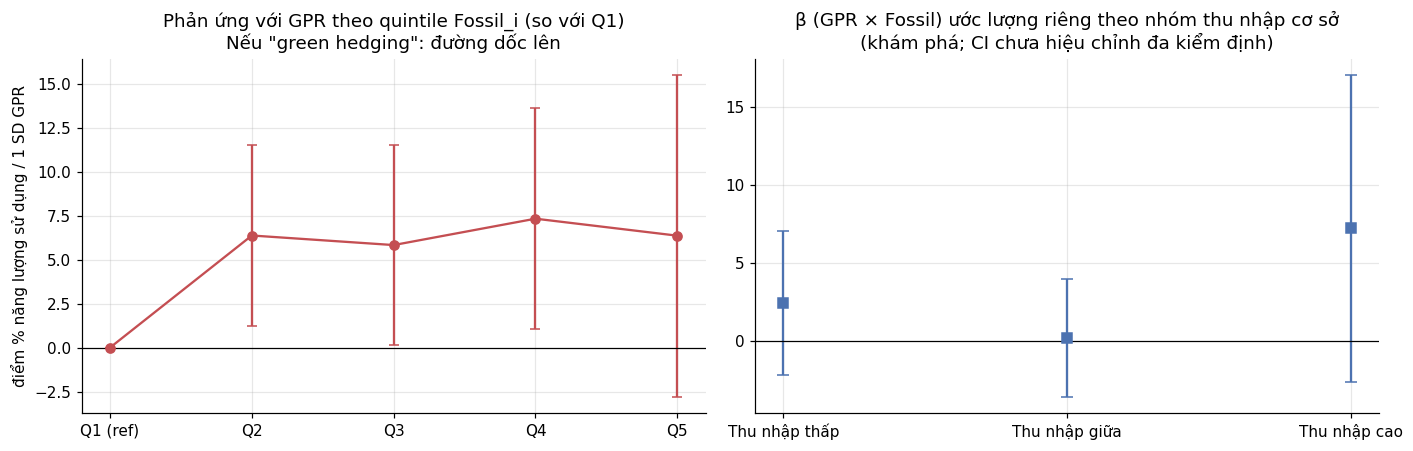

In [10]:
cmap = bs_ok.F; q3 = pd.qcut(cmap, 3, labels=[0, 1, 2]).astype(int); q5 = pd.qcut(cmap, 5, labels=range(5)).astype(int)
dm['g3'] = dm.country_code.map(q3); dm['g5'] = dm.country_code.map(q5)
for k in (1, 2): dm[f'D3_{k}'] = dm.z * (dm.g3 == k)
for k in range(1, 5): dm[f'D5_{k}'] = dm.z * (dm.g5 == k)
dm['F2'] = dm.F**2 - (bs_ok.F**2).mean(); dm['DF2'] = dm.z * dm.F2

rh3 = fit_panel(dm, 'energy_imports_net', ['D3_1', 'D3_2'] + ZX)
rh5 = fit_panel(dm, 'energy_imports_net', [f'D5_{k}' for k in range(1, 5)] + ZX)
rq  = fit_panel(dm, 'energy_imports_net', ['D', 'DF2'] + ZX)
tr_ = pd.DataFrame({'β so với nhóm thấp': rh3.params[['D3_1', 'D3_2']].values, 'SE': rh3.std_errors[['D3_1', 'D3_2']].values,
                    'p': rh3.pvalues[['D3_1', 'D3_2']].values}, index=['Tercile giữa', 'Tercile cao'])
tr_['CI_lo'], tr_['CI_hi'] = tr_['β so với nhóm thấp']-1.96*tr_.SE, tr_['β so với nhóm thấp']+1.96*tr_.SE
tr_.round(4).to_csv('output/table5_heterogeneity_terciles.csv'); display(tr_.round(4))
w_equal = rh5.wald_test(formula=' = '.join([f'D5_{k}' for k in range(1, 5)]) + ' = 0') if False else None
b5 = rh5.params[[f'D5_{k}' for k in range(1, 5)]].values; V5 = rh5.cov.loc[[f'D5_{k}' for k in range(1, 5)], [f'D5_{k}' for k in range(1, 5)]].values
W5 = float(b5 @ np.linalg.solve(V5, b5)); p5 = stats.f.sf(W5/4, 4, dm.country_code.nunique()-1)
print(f'Wald: 4 hệ số quintile bằng 0 đồng thời: F = {W5/4:.2f}, p = {p5:.3f}')
prof = bs_ok.assign(q5=pd.qcut(bs_ok.F, 5, labels=range(1, 6)), gdp0=np.exp(bs_ok.lgdp0)).groupby('q5').agg(n_nước=('F', 'size'), fossil_min=('fossil0', 'min'), fossil_max=('fossil0', 'max'), GDP_trung_vị=('gdp0', 'median')).round(1)
prof.to_csv('output/table5b_quintile_profile.csv'); print('Hồ sơ các quintile của Fossil_i:'); display(prof)
print(f'Phi tuyến (GPR × Fossil²): hệ số = {rq.params["DF2"]:.3f}, p = {rq.pvalues["DF2"]:.3f}')

# dị biệt theo thu nhập cơ sở, ước lượng riêng từng nhóm
inc = pd.qcut(bs_ok.lgdp0, 3, labels=['Thu nhập thấp', 'Thu nhập giữa', 'Thu nhập cao']); dm['inc'] = dm.country_code.map(inc).astype(str)
rows = []
for g in ['Thu nhập thấp', 'Thu nhập giữa', 'Thu nhập cao']:
    s = dm[dm.inc == g]; r = fit_panel(s, 'energy_imports_net', ['D'] + ZX); rows.append(dict(Nhóm=g, β=r.params['D'], SE=r.std_errors['D'], p=r.pvalues['D'], N=int(r.nobs), Cụm=s.country_code.nunique()))
ti = pd.DataFrame(rows).set_index('Nhóm'); order = ti.p.sort_values().index; m = len(ti)
ti['p_Holm'] = np.nan
run = 0
for i, g in enumerate(order): run = max(run, min(1, ti.p[g]*(m-i))); ti.loc[g, 'p_Holm'] = run
ti.round(4).to_csv('output/table6_heterogeneity_income.csv'); display(ti.round(4))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
lab = ['Q1 (ref)', 'Q2', 'Q3', 'Q4', 'Q5']; cq = np.r_[0, b5]; sq = np.r_[0, np.sqrt(np.diag(V5))]
ax[0].errorbar(range(5), cq, yerr=1.96*sq, fmt='o-', capsize=3, c='#C44E52'); ax[0].axhline(0, c='k', lw=.8); ax[0].set_xticks(range(5)); ax[0].set_xticklabels(lab)
ax[0].set_title('Phản ứng với GPR theo quintile Fossil_i (so với Q1)\nNếu "green hedging": đường dốc lên'); ax[0].set_ylabel('điểm % năng lượng sử dụng / 1 SD GPR')
ax[1].errorbar(range(3), ti.β, yerr=1.96*ti.SE, fmt='s', capsize=4, c='#4C72B0'); ax[1].axhline(0, c='k', lw=.8); ax[1].set_xticks(range(3)); ax[1].set_xticklabels(ti.index)
ax[1].set_title('β (GPR × Fossil) ước lượng riêng theo nhóm thu nhập cơ sở\n(khám phá; CI chưa hiệu chỉnh đa kiểm định)')
plt.tight_layout(); plt.savefig('output/fig_heterogeneity.png', dpi=150, bbox_inches='tight'); plt.show()

## 7. Kiểm định phản biện (refutation) — tiêu chí khai báo trước, PASS/FAIL tính bằng mã

Mỗi kiểm định có **tiêu chí số học** ở `CRITERIA` (ô cấu hình đầu notebook). Kết quả `PASS/FAIL` được sinh bởi phép so sánh, không in cứng.

| Kiểm định | Ý nghĩa | Tiêu chí |
|---|---|---|
| **Placebo – hoán vị chuỗi GPR theo năm** (2000 lần) | Gán ngẫu nhiên các giá trị GPR cho các năm; phản ánh *kích thước* của kiểm định và cho **p-value hoán vị** (randomization inference — phù hợp khi treatment chỉ có 13 giá trị) | Tỷ lệ bác bỏ ở mức 5% nằm trong [2%, 8%] |
| **Placebo – hoán vị mức phơi nhiễm giữa các nước** (2000 lần) | Gán ngẫu nhiên Fossil_i cho các nước | như trên |
| **Lead test** | `GPR_{t+1} × Fossil_i` không được "dự báo" Y_t | p > 0.10 |
| **Outcome placebo** | Đô thị hóa, dân số không được phản ứng với GPR × Fossil trong thời gian ngắn | p > 0.10 |
| **Random common cause** (500 lần) | Thêm đặc điểm ngẫu nhiên × GPR_t | median |Δβ| < 0.25 SE và dấu giữ nguyên ≥ 95% |
| **Tập con 80% quốc gia** (1000 lần), bỏ từng năm, bỏ từng nước | Độ ổn định | dấu giữ nguyên ≥ 90%; percentile 95 của |Δβ| ≤ 1 SE |


Kiểm tra hàm nhanh vs linearmodels: β 2.3200 vs 2.3200; SE 1.5366 vs 1.5311


p-value hoán vị (randomization inference) cho β chính = 2.32:  theo năm: 0.016 | theo nước: 0.005


,Thống_kê,Tiêu_chí,Kết_quả
Kiểm_định,,,
Placebo: hoán vị GPR theo năm,mean β_placebo = 0.03; tỷ lệ bác bỏ 5% = 0.001,"tỷ lệ bác bỏ ∈ [0.02, 0.08]",FAIL
Placebo: hoán vị Fossil_i giữa các nước,mean β_placebo = -0.00; tỷ lệ bác bỏ 5% = 0.051,"tỷ lệ bác bỏ ∈ [0.02, 0.08]",PASS
Lead test: GPR_{t+1} × Fossil_i,β_lead = 1.60 (p = 0.196),p > 0.1,PASS
Outcome placebo: Đô thị hóa,β = -0.1060 (p = 0.069),p > 0.1,FAIL
Outcome placebo: log(dân số),β = -0.0015 (p = 0.256),p > 0.1,PASS
Random common cause (500 lần),median |Δβ| = 0.022 SE; giữ dấu 100.0%,< 0.25 SE và ≥ 95%,PASS
Tập con 80% quốc gia (1000 lần),"giữ dấu 99.1%; p95 |Δβ| = 1.01 SE; β ∈ [0.58, 3.63]",dấu ≥ 90% và p95 ≤ 1.0 SE,FAIL
Bỏ lần lượt từng năm (13 mô hình),"β ∈ [2.00, 2.68]; năm ảnh hưởng nhất: 2020",dấu giữ nguyên ở mọi mô hình và max |Δβ| ≤ 1.0 SE,PASS
Bỏ lần lượt từng quốc gia (128 mô hình),"β ∈ [1.53, 2.84]; nước ảnh hưởng nhất: Norway (β=1.53)",dấu giữ nguyên ở mọi mô hình và max |Δβ| ≤ 1.0 SE,PASS


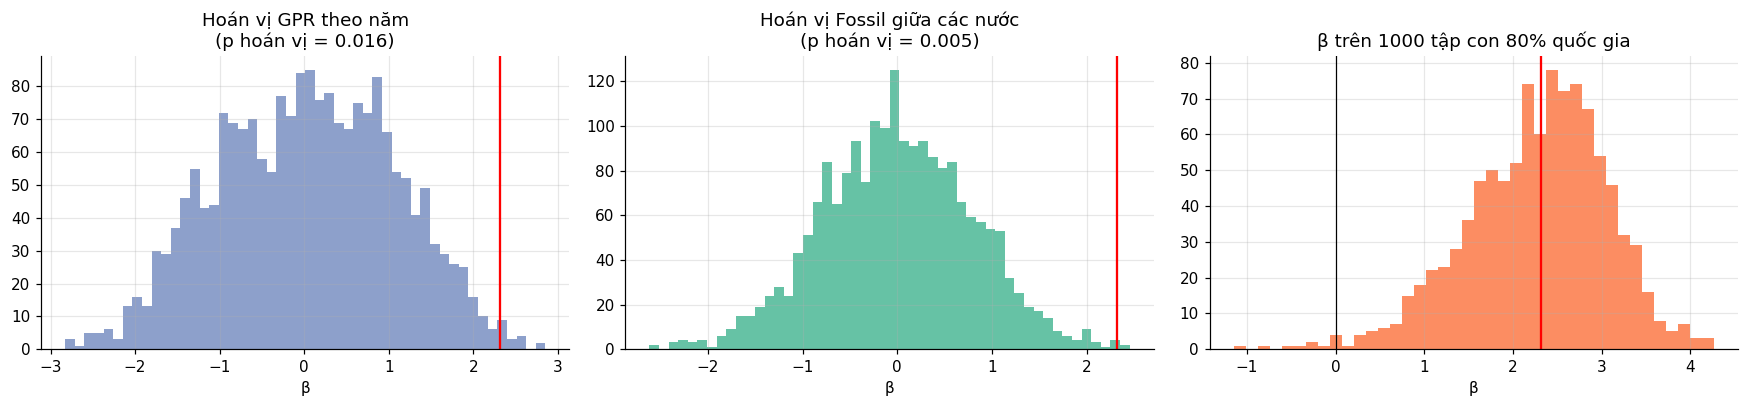

In [11]:
ent, tim = dm.ent.values, dm.tim.values; y = dm.energy_imports_net.values
Zb_mat = dm[[c+'_s' for c in ZB]].values; F_vec = dm.F.values
z_year = np.array([zmap[yr] for yr in range(dm.year.min(), dm.year.max()+1)])   # 13 giá trị
F_cty = dm.groupby('ent').F.first().values
yd = demean_2way(y, ent, tim); KX = ent.max()+tim.max()+1

def beta_fast(zt, Fv, extra=None):
    X = np.column_stack([zt*Fv, Zb_mat*zt[:, None]] + ([extra] if extra is not None else []))
    Xd = demean_2way(X, ent, tim); b, se, _ = cluster_ols(yd, Xd, ent, k_extra=KX); return b[0], se[0]

b_chk, se_chk = beta_fast(dm.z.values, F_vec)
print(f'Kiểm tra hàm nhanh vs linearmodels: β {b_chk:.4f} vs {B:.4f}; SE {se_chk:.4f} vs {SE_B:.4f}')
assert abs(b_chk - B) < 1e-6

REF = []   # bảng kết quả refutation
def add(test, stat, crit, ok): REF.append(dict(Kiểm_định=test, Thống_kê=stat, Tiêu_chí=crit, Kết_quả='PASS' if ok else 'FAIL'))

# (a) hoán vị GPR theo năm
pa = np.array([beta_fast(RNG.permutation(z_year)[tim], F_vec) for _ in range(N_PERM)])
size_a = np.mean(np.abs(pa[:, 0]/pa[:, 1]) > 1.96); ri_a = (1 + np.sum(np.abs(pa[:, 0]) >= abs(B)))/(1 + N_PERM)
lo, hi = CRITERIA['placebo_size']
add('Placebo: hoán vị GPR theo năm', f'mean β_placebo = {pa[:,0].mean():.2f}; tỷ lệ bác bỏ 5% = {size_a:.3f}', f'tỷ lệ bác bỏ ∈ [{lo}, {hi}]', lo <= size_a <= hi)
# (b) hoán vị phơi nhiễm giữa các nước
pb = np.array([beta_fast(dm.z.values, RNG.permutation(F_cty)[ent]) for _ in range(N_PERM)])
size_b = np.mean(np.abs(pb[:, 0]/pb[:, 1]) > 1.96); ri_b = (1 + np.sum(np.abs(pb[:, 0]) >= abs(B)))/(1 + N_PERM)
add('Placebo: hoán vị Fossil_i giữa các nước', f'mean β_placebo = {pb[:,0].mean():.2f}; tỷ lệ bác bỏ 5% = {size_b:.3f}', f'tỷ lệ bác bỏ ∈ [{lo}, {hi}]', lo <= size_b <= hi)
print(f'p-value hoán vị (randomization inference) cho β chính = {B:.2f}:  theo năm: {ri_a:.3f} | theo nước: {ri_b:.3f}')

# (c) lead test
rl = fit_panel(dm, 'energy_imports_net', ['D', 'D_lead'] + ZX); pl = rl.pvalues['D_lead']
add('Lead test: GPR_{t+1} × Fossil_i', f'β_lead = {rl.params["D_lead"]:.2f} (p = {pl:.3f})', f'p > {CRITERIA["lead_p_min"]}', pl > CRITERIA['lead_p_min'])
# (d) outcome placebo
for v, nm in [('urbanization', 'Đô thị hóa'), ('log_population', 'log(dân số)')]:
    rp = fit_panel(dm, v, ['D'] + ZX); add(f'Outcome placebo: {nm}', f'β = {rp.params["D"]:.4f} (p = {rp.pvalues["D"]:.3f})', f'p > {CRITERIA["placebo_out_p"]}', rp.pvalues['D'] > CRITERIA['placebo_out_p'])
# (e) random common cause
rc = np.array([beta_fast(dm.z.values, F_vec, extra=(RNG.normal(size=ent.max()+1)[ent])*dm.z.values)[0] for _ in range(N_RCC)]) - B
med_shift = np.median(np.abs(rc))/SE_B; sign_rc = np.mean(np.sign(rc + B) == np.sign(B))
add('Random common cause (500 lần)', f'median |Δβ| = {med_shift:.3f} SE; giữ dấu {sign_rc:.1%}', f'< {CRITERIA["rcc_shift_se"]} SE và ≥ {CRITERIA["rcc_sign"]:.0%}', med_shift < CRITERIA['rcc_shift_se'] and sign_rc >= CRITERIA['rcc_sign'])
# (f) tập con
Xfull = np.column_stack([dm.D.values, dm[ZX].values]); sub = []
for _ in range(N_SUBSET):
    keep = RNG.random(ent.max()+1) < .8; m = keep[ent]
    sub.append(twfe(y[m], Xfull[m], pd.factorize(ent[m])[0], pd.factorize(tim[m])[0])[0][0])
sub = np.array(sub); sign_s = np.mean(np.sign(sub) == np.sign(B)); p95 = np.percentile(np.abs(sub - B), 95)/SE_B
add('Tập con 80% quốc gia (1000 lần)', f'giữ dấu {sign_s:.1%}; p95 |Δβ| = {p95:.2f} SE; β ∈ [{np.percentile(sub,2.5):.2f}, {np.percentile(sub,97.5):.2f}]',
    f'dấu ≥ {CRITERIA["subset_sign"]:.0%} và p95 ≤ {CRITERIA["subset_shift_se"]} SE', sign_s >= CRITERIA['subset_sign'] and p95 <= CRITERIA['subset_shift_se'])
loyo = np.array([twfe(y[tim != t], Xfull[tim != t], pd.factorize(ent[tim != t])[0], pd.factorize(tim[tim != t])[0])[0][0] for t in np.unique(tim)])
add('Bỏ lần lượt từng năm (13 mô hình)', f'β ∈ [{loyo.min():.2f}, {loyo.max():.2f}]; năm ảnh hưởng nhất: {dm.year.min()+int(np.argmax(np.abs(loyo-B)))}',
    f'dấu giữ nguyên ở mọi mô hình và max |Δβ| ≤ {CRITERIA["subset_shift_se"]} SE', bool(np.all(np.sign(loyo) == np.sign(B)) and np.max(np.abs(loyo-B))/SE_B <= CRITERIA['subset_shift_se']))
cty = np.unique(ent); loco = np.array([twfe(y[ent != c], Xfull[ent != c], pd.factorize(ent[ent != c])[0], pd.factorize(tim[ent != c])[0])[0][0] for c in cty])
names = dm.groupby('ent').country_name.first().values; inf = int(np.argmax(np.abs(loco-B)))
add('Bỏ lần lượt từng quốc gia (128 mô hình)', f'β ∈ [{loco.min():.2f}, {loco.max():.2f}]; nước ảnh hưởng nhất: {names[inf]} (β={loco[inf]:.2f})',
    f'dấu giữ nguyên ở mọi mô hình và max |Δβ| ≤ {CRITERIA["subset_shift_se"]} SE', bool(np.all(np.sign(loco) == np.sign(B)) and np.max(np.abs(loco-B))/SE_B <= CRITERIA['subset_shift_se']))

t5 = pd.DataFrame(REF).set_index('Kiểm_định'); t5.to_csv('output/table7_refutation.csv'); pd.set_option('display.max_colwidth', 120); display(t5)

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
ax[0].hist(pa[:, 0], 50, color='#8DA0CB'); ax[0].axvline(B, c='r'); ax[0].set_title(f'Hoán vị GPR theo năm\n(p hoán vị = {ri_a:.3f})')
ax[1].hist(pb[:, 0], 50, color='#66C2A5'); ax[1].axvline(B, c='r'); ax[1].set_title(f'Hoán vị Fossil giữa các nước\n(p hoán vị = {ri_b:.3f})')
ax[2].hist(sub, 40, color='#FC8D62'); ax[2].axvline(B, c='r'); ax[2].axvline(0, c='k', lw=.8); ax[2].set_title('β trên 1000 tập con 80% quốc gia')
for a in ax: a.set_xlabel('β')
plt.tight_layout(); plt.savefig('output/fig_refutation.png', dpi=150, bbox_inches='tight'); plt.show()

In [12]:
# Độ nhạy với biến gây nhiễu không quan sát (Cinelli & Hazlett 2020, robustness value) — thay cho "E-value" không hợp lệ ở bản cũ
G_ = dm.country_code.nunique(); dof = G_ - 1; tval = B/SE_B; f = abs(tval)/np.sqrt(dof)
rv = 0.5*(np.sqrt(f**4 + 4*f**2) - f**2)
fa = f - stats.t.ppf(.975, dof-1)/np.sqrt(dof-1); rv_a = 0.5*(np.sqrt(fa**4 + 4*fa**2) - fa**2) if fa > 0 else 0.0
print(f't = {tval:.2f}; RV(q=1) = {rv:.3f}: biến gây nhiễu phải giải thích ≥ {rv:.1%} phương sai còn lại của cả D lẫn Y để đưa β về 0')
print(f'RV(q=1, α=5%) = {rv_a:.3f}  ' + ('=> CI 95% chứa 0 nên RV = 0: ngay cả confounder rất yếu cũng đủ làm kết quả không còn khác 0.' if rv_a == 0 else ''))

# Minh họa quy mô hiệu ứng (KHÔNG phải khuyến nghị chính sách)
ci = RES_MAIN.conf_int().loc['D']; dF = -10/SD_F; z22 = zmap[2022]
scen = pd.DataFrame({
    'Kịch bản': ['GPR +1 SD, nước Fossil +1 SD vs trung bình', f'GPR 2022 (≈{z22:.1f} SD so với TB), nước Fossil +1 SD', f'GPR +1 SD, giảm Fossil 10 điểm % (≈{dF:.2f} SD)'],
    'Δ Nhập khẩu ròng (điểm %)': [B, B*z22, B*dF], 'CI_lo': [ci.iloc[0], ci.iloc[0]*z22, ci.iloc[1]*dF], 'CI_hi': [ci.iloc[1], ci.iloc[1]*z22, ci.iloc[0]*dF]}).set_index('Kịch bản')
scen.round(2).to_csv('output/table8_scale.csv'); display(scen.round(2))
print(f'So sánh: độ lệch chuẩn của Y = {dm.energy_imports_net.std():.0f} điểm %; trung vị |Y| = {dm.energy_imports_net.abs().median():.0f}. Mọi CI trên đều chứa 0 ⇒ không đủ cơ sở để diễn giải như tác động chính sách.')

t = 1.52; RV(q=1) = 0.126: biến gây nhiễu phải giải thích ≥ 12.6% phương sai còn lại của cả D lẫn Y để đưa β về 0
RV(q=1, α=5%) = 0.000  => CI 95% chứa 0 nên RV = 0: ngay cả confounder rất yếu cũng đủ làm kết quả không còn khác 0.


,Δ Nhập khẩu ròng (điểm %),CI_lo,CI_hi
Kịch bản,,,
"GPR +1 SD, nước Fossil +1 SD vs trung bình",2.32,-0.68,5.32
"GPR 2022 (≈2.3 SD so với TB), nước Fossil +1 SD",5.23,-1.54,11.99
"GPR +1 SD, giảm Fossil 10 điểm % (≈-0.37 SD)",-0.86,-1.97,0.25


So sánh: độ lệch chuẩn của Y = 164 điểm %; trung vị |Y| = 53. Mọi CI trên đều chứa 0 ⇒ không đủ cơ sở để diễn giải như tác động chính sách.


### 7.1 Giải thích các kết quả FAIL và kiểm tra bổ sung (**post-hoc**)

Ba kiểm định FAIL cần đọc đúng bản chất, **không** điều chỉnh tiêu chí sau khi đã thấy kết quả:

1. **Placebo hoán vị theo năm — tỷ lệ bác bỏ ≈ 0%** (dưới ngưỡng 2%): suy luận cluster theo quốc gia là *bảo thủ* trong thiết kế này (cú sốc chung theo năm tạo tương quan chéo giữa các nước mà cluster theo nước không bắt hết). Ngược lại, p-value hoán vị nhỏ hơn nhiều p-value cluster, vì độ lệch chuẩn của β dưới hoán vị (≈1.0) nhỏ hơn SE cluster (≈1.5). Hai cách suy luận cho kết luận khác nhau; p-value hoán vị đòi hỏi các năm (hoặc các nước) *hoán đổi được cho nhau* (as-if random). Giả định này **yếu**: chuỗi GPR có xu hướng/dạng chữ U, và hoán vị Fossil_i giữa các nước phá vỡ mối liên hệ giữa mức phơi nhiễm và *phương sai nhiễu* (các nước xuất khẩu năng lượng có Y dao động rất lớn).
2. **Outcome placebo đô thị hóa (p≈0.07)** và **tập con 80% (p95 = 1.01 SE, sát ngưỡng 1.0)**: cả hai đều sát ngưỡng. Lưu ý riêng cho tập con: với mẫu con 80%, độ biến thiên do chọn mẫu thuần túy đã khoảng 0.98 SE ở percentile 95, nên tiêu chí 1.0 SE khai báo ban đầu *gần như ngang mức nhiễu*; ta giữ nguyên kết quả FAIL và nêu rõ điều này.
3. Placebo đô thị hóa gợi ý có thể có **xu hướng khác biệt theo mức phơi nhiễm** (nước phụ thuộc hóa thạch có thể có quỹ đạo phát triển riêng). Ô dưới kiểm tra giả thuyết này. Đây là kiểm tra **bổ sung sau khi thấy kết quả**, được ghi nhãn "post-hoc" và đưa vào Bảng 2.

In [13]:
dm['t'] = dm.year - 2016; dm['Ft'] = dm.F*dm.t; dm['Ft2'] = dm.F*dm.t**2
for c in ZB: dm['t_'+c] = dm[c+'_s']*dm.t
TR = ['t_'+c for c in ZB]
extra = []
rA = fit_panel(dm, 'energy_imports_net', ['D', 'Ft'] + ZX);               extra.append(row(rA, '', dm, label='(10) post-hoc: + Fossil_i × xu hướng tuyến tính'))
rB = fit_panel(dm, 'energy_imports_net', ['D', 'Ft'] + ZX + TR);           extra.append(row(rB, '', dm, label='(11) post-hoc: + cả Z_i × xu hướng tuyến tính'))
rC = fit_panel(dm, 'energy_imports_net', ['D', 'Ft', 'Ft2'] + ZX);         extra.append(row(rC, '', dm, label='(12) post-hoc: + Fossil_i × (t, t²)'))
t2 = pd.concat([t2.drop(columns='Ý nghĩa 5%'), pd.DataFrame(extra).set_index('Đặc_tả')]); t2['Ý nghĩa 5%'] = np.where(t2.p < .05, 'Có', 'Không')
t2.round(4).to_csv('output/table2_main.csv'); display(t2.round(4).iloc[-3:])
ru = fit_panel(dm, 'urbanization', ['D', 'Ft'] + ZX)
print(f'Placebo đô thị hóa khi thêm Fossil×xu hướng: β = {ru.params["D"]:.4f}, p = {ru.pvalues["D"]:.3f} (trước đó p = 0.069)')
Xt = np.column_stack([np.ones(len(z_year)), np.arange(len(z_year)), np.arange(len(z_year))**2]); r2z = 1 - np.sum((z_year - Xt @ np.linalg.lstsq(Xt, z_year, rcond=None)[0])**2)/np.sum((z_year - z_year.mean())**2)
print(f'Chuỗi GPR 13 năm: R² khi hồi quy lên (1, t, t²) = {r2z:.2f} ⇒ khoảng một nửa biến thiên của GPR (dạng chữ U) trùng với xu hướng bậc 2; chỉ {1-r2z:.0%} biến thiên còn lại là độc lập với xu hướng đó.')
print(f'Độ lệch chuẩn của β dưới hoán vị: theo năm = {pa[:,0].std():.2f}, theo nước = {pb[:,0].std():.2f}  so với SE cluster = {SE_B:.2f}  (giải thích vì sao p hoán vị < p cluster)')
print(f'\nβ chính = {B:.2f} → {rA.params["D"]:.2f} (xu hướng tuyến tính) → {rC.params["D"]:.2f} (bậc 2, p = {rC.pvalues["D"]:.2f}): hiệu ứng KHÔNG vững khi cho phép nước có Fossil khác nhau đi theo quỹ đạo thời gian khác nhau.')

,β,SE,p,CI_lo,CI_hi,N,Cụm,Ý nghĩa 5%
Đặc_tả,,,,,,,,
(10) post-hoc: + Fossil_i × xu hướng tuyến tính,1.9033,1.5523,0.2204,-1.1417,4.9483,1636,128,Không
(11) post-hoc: + cả Z_i × xu hướng tuyến tính,2.2986,1.5261,0.1322,-0.6949,5.2922,1636,128,Không
"(12) post-hoc: + Fossil_i × (t, t²)",0.7874,1.5912,0.6208,-2.3338,3.9086,1636,128,Không


Placebo đô thị hóa khi thêm Fossil×xu hướng: β = -0.0689, p = 0.274 (trước đó p = 0.069)
Chuỗi GPR 13 năm: R² khi hồi quy lên (1, t, t²) = 0.52 ⇒ khoảng một nửa biến thiên của GPR (dạng chữ U) trùng với xu hướng bậc 2; chỉ 48% biến thiên còn lại là độc lập với xu hướng đó.
Độ lệch chuẩn của β dưới hoán vị: theo năm = 1.04, theo nước = 0.80  so với SE cluster = 1.53  (giải thích vì sao p hoán vị < p cluster)

β chính = 2.32 → 1.90 (xu hướng tuyến tính) → 0.79 (bậc 2, p = 0.62): hiệu ứng KHÔNG vững khi cho phép nước có Fossil khác nhau đi theo quỹ đạo thời gian khác nhau.


In [14]:
# Sổ cái kết luận: mỗi tuyên bố gắn với bằng chứng và mức độ hỗ trợ (sinh tự động từ kết quả ở trên)
n_sig = int((t2.p < .05).sum()); n_pos = int((t2.β > 0).sum())
ledger = pd.DataFrame([
  ('Xu hướng song song trước 2014', f'Wald p = {wA["p"]:.2f} (3 lead); MDE ≈ {2.8*wA["mean_lead_se"]:.1f} ≫ |β| = {abs(B):.1f}', 'Không phát hiện vi phạm, nhưng kiểm định thiếu lực — KHÔNG thể khẳng định song song'),
  ('GPR × phơi nhiễm hóa thạch làm tăng nhập khẩu ròng', f'β = {B:.2f}, p = {P_B:.2f}; dương ở {n_pos}/{len(t2)} đặc tả nhưng p<0.05 ở {n_sig}/{len(t2)}', 'Dấu nhất quán, hiệu ứng không có ý nghĩa thống kê vững ⇒ chưa đủ để khẳng định nhân quả'),
  ('DML (Ridge/Lasso/RF)', ', '.join(f'{k.replace("DML + ","")}: {t4.loc[k,"β"]:.2f} (p={t4.loc[k,"p"]:.2f})' for k in ['DML + Ridge', 'DML + Lasso', 'DML + RandomForest']), 'Biên giới ý nghĩa (p≈0.05–0.10), phụ thuộc thuật toán — không vững'),
  ('"Green hedging" (độ nhạy tăng theo Fossil)', f'Wald 4 quintile p = {p5:.2f}; phi tuyến p = {rq.pvalues["DF2"]:.2f}', 'Không có bằng chứng thống kê về gradient; chỉ là giả thuyết cần kiểm chứng'),
  ('Suy luận hoán vị (randomization inference)', f'p hoán vị theo năm = {ri_a:.3f}; theo nước = {ri_b:.3f} (so với p cluster = {P_B:.2f})', 'Hai cách suy luận bất đồng; giả định hoán đổi được của hoán vị theo năm yếu ⇒ không thể dựa riêng vào p hoán vị'),
  ('Cho phép xu hướng khác biệt theo Fossil_i', f'β: {B:.2f} → {rA.params["D"]:.2f} (tuyến tính) → {rC.params["D"]:.2f} (bậc 2, p = {rC.pvalues["D"]:.2f})', 'Hiệu ứng suy giảm mạnh; GPR (chữ U) khó tách khỏi xu hướng phi tuyến theo thời gian'),
  ('Kiểm định phản biện', f'{(t5.Kết_quả=="PASS").sum()} PASS / {(t5.Kết_quả=="FAIL").sum()} FAIL trên {len(t5)} kiểm định', 'Xem Bảng 7 để biết kiểm định nào thất bại'),
], columns=['Tuyên bố', 'Bằng chứng', 'Đánh giá']).set_index('Tuyên bố')
pd.set_option('display.max_colwidth', 200); display(ledger); ledger.to_csv('output/ledger.csv')

summary = dict(main=dict(beta=B, se=SE_B, p=P_B, n=int(RES_MAIN.nobs), clusters=G_, sd_gpr=SD_GPR, sd_fossil=SD_F, sd_y=float(dm.energy_imports_net.std())),
               ri_year=ri_a, ri_country=ri_b, rv=rv, rv_alpha=rv_a, pretrend=ES, dml={k: dict(beta=float(v.β), se=float(v.SE), p=float(v.p)) for k, v in t4.iterrows()},
               econml=ECO, quintile_wald_p=float(p5), quad_p=float(rq.pvalues['DF2']), refutation=t5.reset_index().to_dict('records'))
json.dump(summary, open('output/results.json', 'w'), ensure_ascii=False, indent=1, default=float)
print('\nĐã lưu: output/*.csv, output/*.png, output/results.json')

,Bằng chứng,Đánh giá
Tuyên bố,,
Xu hướng song song trước 2014,Wald p = 0.73 (3 lead); MDE ≈ 13.4 ≫ |β| = 2.3,"Không phát hiện vi phạm, nhưng kiểm định thiếu lực — KHÔNG thể khẳng định song song"
GPR × phơi nhiễm hóa thạch làm tăng nhập khẩu ròng,"β = 2.32, p = 0.13; dương ở 12/12 đặc tả nhưng p<0.05 ở 0/12","Dấu nhất quán, hiệu ứng không có ý nghĩa thống kê vững ⇒ chưa đủ để khẳng định nhân quả"
DML (Ridge/Lasso/RF),"Ridge: 2.96 (p=0.05), Lasso: 2.75 (p=0.05), RandomForest: 2.67 (p=0.10)","Biên giới ý nghĩa (p≈0.05–0.10), phụ thuộc thuật toán — không vững"
"""Green hedging"" (độ nhạy tăng theo Fossil)",Wald 4 quintile p = 0.15; phi tuyến p = 0.77,Không có bằng chứng thống kê về gradient; chỉ là giả thuyết cần kiểm chứng
Suy luận hoán vị (randomization inference),p hoán vị theo năm = 0.016; theo nước = 0.005 (so với p cluster = 0.13),Hai cách suy luận bất đồng; giả định hoán đổi được của hoán vị theo năm yếu ⇒ không thể dựa riêng vào p hoán vị
Cho phép xu hướng khác biệt theo Fossil_i,"β: 2.32 → 1.90 (tuyến tính) → 0.79 (bậc 2, p = 0.62)",Hiệu ứng suy giảm mạnh; GPR (chữ U) khó tách khỏi xu hướng phi tuyến theo thời gian
Kiểm định phản biện,6 PASS / 3 FAIL trên 9 kiểm định,Xem Bảng 7 để biết kiểm định nào thất bại



Đã lưu: output/*.csv, output/*.png, output/results.json


## 8. Kết luận 

**Những gì có thể nói**

1. **Dấu hiệu thực nghiệm:** ở cả 12 đặc tả (9 đặc tả định trước + 3 post-hoc), hệ số `GPR_t × Fossil_i` đều **dương** (khoảng +0.8 đến +2.7 điểm % năng lượng sử dụng cho 1 SD GPR × 1 SD Fossil; đặc tả (7) dùng thang asinh nên không so sánh trực tiếp) — tương thích với giả thuyết nước ít dùng tái tạo nhạy hơn với rủi ro địa chính trị.
2. **Nhưng chưa có bằng chứng vững:** với SE cluster, **không đặc tả nào** có p < 0.05 (đặc tả chính p ≈ 0.13, CI95% ≈ [−0.7; 5.3]). Độ lớn hiệu ứng nhỏ so với độ phân tán của Y (≈ 0.014 SD của Y). DML cho p sát ngưỡng (≈ 0.05 với Ridge/Lasso, ≈ 0.10 với Random Forest) và không ổn định giữa các lần chia mẫu.
3. **Suy luận không nhất quán:** p-value hoán vị (≈ 0.016 theo năm, ≈ 0.005 theo nước) nhỏ hơn nhiều p cluster, nhưng giả định hoán đổi được của các năm là yếu.
4. **Nhận dạng dễ vỡ:** khi cho phép nước có Fossil khác nhau đi theo xu hướng thời gian riêng, β giảm còn ≈ 1.9 (tuyến tính) và ≈ 0.8 (bậc hai, p ≈ 0.6). Khoảng một nửa biến thiên của chuỗi GPR (dạng chữ U, R² ≈ 0.5) trùng với một xu hướng bậc hai, nên *biến thiên thời gian độc lập còn lại của GPR hạn chế để tách khỏi các xu hướng phi tuyến*.
5. **Xu hướng song song chưa được chứng minh:** các kiểm định Wald trước sự kiện không bác bỏ (p = 0.30–0.73), nhưng *minimum detectable effect* (≈ 10–20 điểm %) lớn gấp nhiều lần hiệu ứng ước lượng ⇒ kiểm định thiếu lực. "Không bác bỏ" ≠ "ủng hộ".
6. **"Green hedging":** không có gradient có ý nghĩa theo tercile/quintile của Fossil (Wald p ≈ 0.15), không có phi tuyến (p ≈ 0.77), không có dị biệt theo thu nhập sau hiệu chỉnh Holm. Hồ sơ quintile cho thấy khác biệt nằm ở *bước nhảy* giữa Q1 và Q2–Q5 (không phải gradient), mà Q1 (Fossil < 49%) lại là nhóm thu nhập thấp (GDP/người trung vị ≈ 4.3 nghìn USD), nơi tỷ trọng "tái tạo" có thể chủ yếu là sinh khối truyền thống — nên không thể diễn giải là "green hedging". Đây là **giả thuyết cần kiểm chứng thêm**, chưa phải phát hiện.

**Những gì KHÔNG được khẳng định:** tác động nhân quả của GPR lên nhập khẩu năng lượng; cơ chế green hedging; các con số chính sách (mọi CI minh họa đều chứa 0).

**Hạn chế còn lại:** (i) chỉ 13 giá trị GPR ⇒ cỡ mẫu hiệu dụng theo thời gian rất nhỏ; (ii) thang đo outcome cần xác nhận với nguồn dữ liệu; (iii) mất mẫu không ngẫu nhiên năm 2023 và thiếu `renewable_share` 2022–2023; (iv) 15/143 nước bị loại vì thiếu dữ liệu cơ sở 2010–2013; (v) mức phơi nhiễm chỉ dựa vào tỷ trọng tái tạo trong *tiêu thụ cuối cùng*, chưa phản ánh tỷ lệ nhập khẩu theo nhiên liệu/đối tác; (vi) các đặc tả 10–12 là post-hoc.

**Hướng mở rộng hợp lý:** dùng biến cú sốc có biến thiên chéo giữa các nước (ví dụ GPR song phương/đối tác thương mại, hoặc mức phụ thuộc vào nhập khẩu từ Nga năm 2013 × cú sốc 2022); thêm dữ liệu giá năng lượng; dùng synthetic DiD / tổng quát hóa với wild cluster bootstrap.